# Week 4: Variational free energy (NumPy)

Week 3's point rule learned a prior variance of zero whenever the generative process
was narrow enough, because it evaluated the gradient of the log joint at the mode of
each posterior and so dropped the posterior's variance. This notebook computes the
numbers of Week 4, which replaces the mode by a recognition distribution $Q$, with
array operations only. Each section ends by comparing its results with the values
printed in the lessons; the comparison fails loudly if they disagree.

### AI use

This course notebook was developed with substantial assistance from Claude
(Anthropic) and Gemini (Google), and revised with Codex (OpenAI), under Jonathan
Shock's direction. AI contributed to explanations and code. See [AI use and attribution](https://shocklab.github.io/Active-Inference-course/ai-use.html)
for the review process and its limits.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import cos, erf, exp, lgamma, log, pi, sqrt
from time import perf_counter

np.set_printoptions(precision=4, suppress=True)
COL = {'accent': '#0f5f57', 'clay': '#9c4d2f', 'blue': '#2c5f8a', 'gold': '#8a6d1f', 'violet': '#6b4a8a'}
E_CONST = exp(1.0)

def check(name, got, key, rtol):
    """Compare a result with the value printed in the lesson (from values.py)."""
    want = EXPECTED[key]
    err = abs(got - want) / max(1.0, abs(want))
    status = "ok" if err <= rtol else "MISMATCH"
    print(f"{status:8s} {name:38s} {got: .10g}   lesson {want: .10g}")
    assert err <= rtol, (name, got, want)

def note(name, got, key):
    """Print an iteration count beside the lesson's. A run that stops at a tolerance near the
    rounding level can take a few more or fewer iterations on another machine, so counts are
    reported, not checked."""
    print(f"{'count':8s} {name:38s} {got: .10g}   lesson {EXPECTED[key]: .10g}")

## 1. Three decompositions and the spike

Lesson 1 writes the free energy of a belief $Q$ after an observation $o$ three ways:
expected energy minus entropy, complexity minus accuracy, and divergence from the
posterior plus surprise. On Week 1's three-state model after a tawny flash, the
three agree for every $Q$, to rounding.

The second half takes Week 2's linear Gaussian model, $d \sim \mathcal{N}(2, 1)$ and
$u \mid d \sim \mathcal{N}(d, 0.1)$ at $u = 0.5$, and a Gaussian belief
$\mathcal{N}(\hat d, \epsilon)$ at the posterior mode. As $\epsilon \to 0$ the
expected energy tends to $-\ell(\hat d)$ while the entropy
$\tfrac12 \ln(2\pi e \epsilon)$ tends to $-\infty$, so the free energy grows
without bound: the free energy of a point mass is infinite.

Q               U        H     comp      acc       KL        F
prior      3.9692   0.7848   0.0000  -3.1843   0.9113   3.1843
unif       3.5208   1.0986   0.3669  -2.0553   0.1491   2.4222
sharp      2.9207   0.1957   2.2664  -0.4586   0.4520   2.7250
post       3.2403   0.9672   0.9396  -1.3335   0.0000   2.2730
ok       F at the widget default                 2.359987204   lesson  2.359987204
ok       KL from the posterior there             0.08696091288   lesson  0.08696091288
ok       surprise of the linear model            1.989320896   lesson  1.989320896
epsilon = 0.0909: U = 2.2093, H = 0.2200, F = 1.9893
epsilon = 0.01: U = 1.7643, H = -0.8836, F = 2.6480
epsilon = 0.0001: U = 1.7099, H = -3.1862, F = 4.8961
epsilon = 1e-08: U = 1.7093, H = -7.7914, F = 9.5007


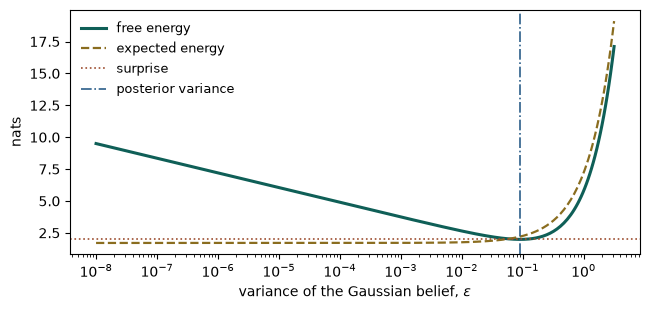

In [2]:
EXPECTED = {
    'w1_def_F': 2.359987203630256,
    'w1_def_klpost': 0.08696091287775494,
    'lin_surp': 1.989320895834108,
    'd_prior_U': 3.9691553494700185,
    'd_prior_H': 0.7848388534803238,
    'd_prior_comp': 0.0,
    'd_prior_acc': -3.1843164959896946,
    'd_prior_klpost': 0.9112902052371933,
    'd_prior_F': 3.1843164959896946,
    'd_unif_U': 3.520783085043174,
    'd_unif_H': 1.0986122886681096,
    'd_unif_comp': 0.36689815162414474,
    'd_unif_acc': -2.0552726447509198,
    'd_unif_klpost': 0.14914450562256337,
    'd_unif_F': 2.4221707963750645,
    'd_sharp_U': 2.920706358054759,
    'd_sharp_H': 0.19567003495657082,
    'd_sharp_comp': 2.266445517110725,
    'd_sharp_acc': -0.4585908059874637,
    'd_sharp_klpost': 0.4520100323456869,
    'd_sharp_F': 2.7250363230981884,
    'd_post_U': 3.240267445737712,
    'd_post_H': 0.9672411549852102,
    'd_post_comp': 0.9395595098030144,
    'd_post_acc': -1.333466780949487,
    'd_post_klpost': 0.0,
    'd_post_F': 2.273026290752502,
    'spike_opt_U': 2.2093117926395953,
    'spike_opt_H': 0.21999089680548745,
    'spike_opt_F': 1.989320895834108,
    'spike_e2_U': 1.7643117926395955,
    'spike_e2_H': -0.883646559789373,
    'spike_e2_F': 2.6479583524289687,
    'spike_e4_U': 1.7098617926395956,
    'spike_e4_H': -3.1862316527834187,
    'spike_e4_F': 4.8960934454230145,
    'spike_e8_U': 1.7093118476395956,
    'spike_e8_H': -7.79140183877151,
    'spike_e8_F': 9.500713686411105,
}

A_MAT = np.array([
    [0.70, 0.15, 0.02],  # tawny flash
    [0.25, 0.75, 0.08],  # branch shakes
    [0.05, 0.10, 0.90],  # quiet
])
PRIOR_3 = np.array([0.08, 0.22, 0.70])

def decompositions(q, o_idx=0):
    q = np.asarray(q, dtype=float)
    lik = A_MAT[o_idx]
    joint = lik * PRIOR_3
    ev = joint.sum()
    post = joint / ev
    m = q > 0
    U = -np.sum(q[m] * np.log(joint[m]))
    H = -np.sum(q[m] * np.log(q[m]))
    comp = np.sum(q[m] * np.log(q[m] / PRIOR_3[m]))
    acc = np.sum(q[m] * np.log(lik[m]))
    klpost = np.sum(q[m] * np.log(q[m] / post[m]))
    F1, F2, F3 = U - H, comp - acc, klpost - log(ev)
    assert abs(F1 - F2) < 1e-14 and abs(F1 - F3) < 1e-14
    return dict(U=U, H=H, comp=comp, acc=acc, klpost=klpost, F=F1)

post_tawny = A_MAT[0] * PRIOR_3 / (A_MAT[0] * PRIOR_3).sum()
candidates = {'prior': PRIOR_3, 'unif': np.full(3, 1 / 3), 'sharp': np.array([0.96, 0.02, 0.02]),
              'post': post_tawny}
print(f"{'Q':8s} {'U':>8s} {'H':>8s} {'comp':>8s} {'acc':>8s} {'KL':>8s} {'F':>8s}")
for tag, q in candidates.items():
    r = decompositions(q)
    print(f"{tag:8s} " + " ".join(f"{r[k]:8.4f}" for k in ('U', 'H', 'comp', 'acc', 'klpost', 'F')))
    for k, v in r.items():
        assert abs(v - EXPECTED[f'd_{tag}_{k}']) < 1e-13
r = decompositions([0.35, 0.40, 0.25])
check('F at the widget default', r['F'], 'w1_def_F', 1e-13)
check('KL from the posterior there', r['klpost'], 'w1_def_klpost', 1e-13)

# the linear Gaussian model and a Gaussian spike at its mode
D_P, V_P, U_O, V_O = 2.0, 1.0, 0.50, 0.10
s_post = 1.0 / (1.0 / V_P + 1.0 / V_O)
d_hat = s_post * (D_P / V_P + U_O / V_O)
ell_hat = (-(d_hat - D_P) ** 2 / (2 * V_P) - 0.5 * log(2 * pi * V_P)
           - (U_O - d_hat) ** 2 / (2 * V_O) - 0.5 * log(2 * pi * V_O))
check('surprise of the linear model', -ell_hat - 0.5 * log(2 * pi * s_post), 'lin_surp', 1e-14)

def spike(eps):
    U = -ell_hat + eps / (2 * s_post)      # E[(d - d_hat)^2] = eps; ell is quadratic
    H = 0.5 * log(2 * pi * E_CONST * eps)
    return U, H, U - H

for tag, eps in (('opt', s_post), ('e2', 1e-2), ('e4', 1e-4), ('e8', 1e-8)):
    U, H, F = spike(eps)
    print(f'epsilon = {eps:.3g}: U = {U:.4f}, H = {H:.4f}, F = {F:.4f}')
    for k, v in (('U', U), ('H', H), ('F', F)):
        assert abs(v - EXPECTED[f'spike_{tag}_{k}']) < 1e-13

eps = np.logspace(-8, 0.5, 300)
UF = np.array([spike(e) for e in eps])
fig, ax = plt.subplots(figsize=(6.6, 3.2))
ax.semilogx(eps, UF[:, 2], color=COL['accent'], lw=2.2, label='free energy')
ax.semilogx(eps, UF[:, 0], color=COL['gold'], lw=1.6, ls='--', label='expected energy')
ax.axhline(EXPECTED['lin_surp'], color=COL['clay'], lw=1.2, ls=':', label='surprise')
ax.axvline(s_post, color=COL['blue'], lw=1.2, ls='-.', label='posterior variance')
ax.set_xlabel(r'variance of the Gaussian belief, $\epsilon$')
ax.set_ylabel('nats')
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 2. Expectation maximisation on Week 3's prior variance

Lesson 4 learns the prior variance $\Sigma_p$ of the linear model
$d \sim \mathcal{N}(2, \Sigma_p)$, $u \mid d \sim \mathcal{N}(d, 1)$ from 200 trials
drawn with $\Sigma_p^{*} = 1$. The E-step sets each $Q_n$ to the exact posterior,
which is Gaussian with variance $\Sigma_p/(\Sigma_p + 1)$; the M-step sets $\Sigma_p$
to the average of $\mathbb{E}_{Q_n}[(d - 2)^2]$. Starting from $\Sigma_p = 0.2$, the
table prints, after each iteration, the new $\Sigma_p$, the bound $-\mathcal{F}$ per
trial at the new $\Sigma_p$ with the old $Q$, and the log evidence per trial, which
must satisfy old evidence $\le$ bound $\le$ new evidence. The point rule, which
replaces each posterior by its mode, is run beside it.

ok       sample second moment S                  1.740985983   lesson  1.740985983
ok       maximum-likelihood variance S - 1       0.7409859833   lesson  0.7409859833
ok       log evidence at 0.2                    -1.735510138   lesson -1.735510138
step   Sigma_p      bound     log ev
   1    0.2150    -1.7342    -1.7328
   2    0.2315    -1.7314    -1.7299
   3    0.2495    -1.7285    -1.7270
   4    0.2691    -1.7255    -1.7240
   5    0.2903    -1.7225    -1.7210
   6    0.3131    -1.7195    -1.7181
count    iterations to converge                  173   lesson  173
ok       converged Sigma_p                       0.7409859833   lesson  0.7409859833
point rule after 40 steps: 0.000e+00


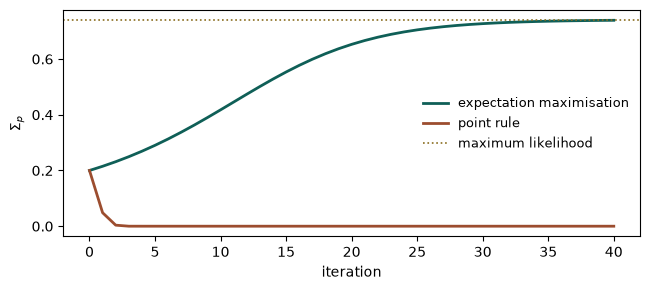

In [3]:
EXPECTED = {
    'em_S_emp': 1.7409859833044785,
    'em_vp_mle': 0.7409859833044785,
    'em_conv_its': 173.0,
    'em_conv_vp': 0.7409859833044731,
    'em_conv_logev': -1.6961643381089149,
    'em_0_logev': -1.7355101379785163,
    'em_1_vp': 0.21502738842512442,
    'em_1_elbo_m': -1.7341656876608524,
    'em_1_logev': -1.7327608296872645,
    'em_2_vp': 0.23150017159118824,
    'em_2_elbo_m': -1.7313645144383059,
    'em_2_logev': -1.7299108337221645,
    'em_3_vp': 0.24950403773307647,
    'em_3_elbo_m': -1.7284728643066167,
    'em_3_logev': -1.7269826958577004,
    'em_4_vp': 0.26910093868055096,
    'em_4_elbo_m': -1.725516708610057,
    'em_4_logev': -1.724006022621648,
    'em_5_vp': 0.2903174663581851,
    'em_5_elbo_m': -1.722529134753208,
    'em_5_logev': -1.7210174187230722,
    'em_6_vp': 0.31313193707314174,
    'em_6_elbo_m': -1.7195499331607602,
    'em_6_logev': -1.7180596495986562,
    'pt_1_vp': 0.04836072175845774,
    'pt_2_vp': 0.0037047536964298013,
    'pt_3_vp': 2.371930680177856e-05,
    'pt_4_vp': 9.794418521033475e-10,
}

def mulberry32(seed):
    """32-bit seeded generator, the same one the course widgets use."""
    a = [seed & 0xFFFFFFFF]
    def imul(x, y):
        return ((x & 0xFFFFFFFF) * (y & 0xFFFFFFFF)) & 0xFFFFFFFF
    def rnd():
        a[0] = (a[0] + 0x6D2B79F5) & 0xFFFFFFFF
        t = imul(a[0] ^ (a[0] >> 15), 1 | a[0])
        t = ((t + imul(t ^ (t >> 7), 61 | t)) & 0xFFFFFFFF) ^ t
        return ((t ^ (t >> 14)) & 0xFFFFFFFF) / 4294967296
    return rnd

def normal(r):
    u1, u2 = r(), r()
    return sqrt(-2.0 * log(1.0 - u1)) * cos(2.0 * pi * u2)

rng = mulberry32(19)
u_em = np.array([2.0 + normal(rng) + normal(rng) for _ in range(200)])
S = float(np.mean((u_em - 2.0) ** 2))
check('sample second moment S', S, 'em_S_emp', 1e-14)
check('maximum-likelihood variance S - 1', S - 1.0, 'em_vp_mle', 1e-14)

def logev(vp):               # log evidence per trial: u ~ N(2, vp + 1)
    return -0.5 * log(2 * pi * (vp + 1)) - 0.5 * S / (vp + 1)

def bound(vp_q, vp):         # -F per trial with Q_n the posterior under vp_q, at prior variance vp
    sp = vp_q / (vp_q + 1)
    sh = vp_q / (vp_q + 1)
    e_dev2 = sp + sh ** 2 * S
    e_res2 = sp + (1 - sh) ** 2 * S
    return (-0.5 * log(2 * pi * vp) - 0.5 * e_dev2 / vp - 0.5 * log(2 * pi) - 0.5 * e_res2
            + 0.5 * log(2 * pi * E_CONST * sp))

def em_step(vp):
    return vp / (vp + 1) + (vp / (vp + 1)) ** 2 * S

vp = 0.20
check('log evidence at 0.2', logev(vp), 'em_0_logev', 1e-14)
print(f"{'step':>4s} {'Sigma_p':>9s} {'bound':>10s} {'log ev':>10s}")
path = [vp]
for step in range(1, 7):
    assert abs(bound(vp, vp) - logev(vp)) < 1e-14       # the E-step closes the gap
    new = em_step(vp)
    b = bound(vp, new)
    assert logev(vp) <= b <= logev(new)
    print(f'{step:4d} {new:9.4f} {b:10.4f} {logev(new):10.4f}')
    for k, v in (('vp', new), ('elbo_m', b), ('logev', logev(new))):
        assert abs(v - EXPECTED[f'em_{step}_{k}']) < 1e-13
    vp = new
    path.append(vp)
its = 6
while abs(em_step(vp) - vp) > 1e-15 and its < 1000:
    vp = em_step(vp)
    path.append(vp)
    its += 1
note('iterations to converge', its, 'em_conv_its')
check('converged Sigma_p', vp, 'em_conv_vp', 1e-12)

vp_pt = 0.20
pt = [vp_pt]
for step in range(1, 41):
    vp_pt = (vp_pt / (vp_pt + 1)) ** 2 * S
    pt.append(vp_pt)
    if step <= 4:
        assert abs(vp_pt - EXPECTED[f'pt_{step}_vp']) < 1e-14
print(f'point rule after 40 steps: {vp_pt:.3e}')

fig, ax = plt.subplots(figsize=(6.6, 3.0))
ax.plot(path[:41], color=COL['accent'], lw=2.0, label='expectation maximisation')
ax.plot(pt, color=COL['clay'], lw=2.0, label='point rule')
ax.axhline(S - 1, color=COL['gold'], ls=':', lw=1.2, label='maximum likelihood')
ax.set_xlabel('iteration')
ax.set_ylabel(r'$\Sigma_p$')
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 3. Coordinate ascent on the noisy-OR model

Lesson 2 approximates Week 1's noisy-OR posterior after the sensor fires,
$P(s_1, s_2 \mid o_1 = 1)$, by a product of two Bernoulli beliefs with means $q_1$ and
$q_2$. Each coordinate update lowers $\mathcal{F}$ by exactly the divergence between
the old and new factor, which the code asserts. Sequential updates from $(0.1, 0.1)$
leave the diagonal and reach an asymmetric minimum; the update map's fixed point on
the diagonal is a saddle, where the map's slope is below $-1$; simultaneous updates
from the diagonal stay on it and settle on a two-cycle whose points are the
coordinates of the two minima. The section ends with the two messages into $s_1$ and
with the free-form coordinate ascent on a Normal-Gamma model, whose exact surprise
comes from one-dimensional quadrature in $\ln \Pi$.

In [4]:
EXPECTED = {
    'nor_surp': 1.7137933777686942,
    'nor_marg_1': 0.5049977522602273,
    'cavi_lim_q1': 0.7626776215118606,
    'cavi_lim_q2': 0.2578574415109314,
    'cavi_lim_F': 2.2127264345469837,
    'cavi_lim_sweeps': 80.0,
    'cavi_sad_q': 0.5119402059903675,
    'cavi_sad_F': 2.226357455472218,
    'cavi_sad_rprime': -1.1010266233109147,
    'cyc_lo': 0.2578574415109325,
    'cyc_hi': 0.7626776215118594,
    'msg_sp_q1': 0.5049977522602273,
    'msg_vm_q1': 0.8656501517837486,
    'ng_surp': 1.9662384871906091,
    'ng_md': 0.6394295229014296,
    'ng_sd': 0.30488196940393136,
    'ng_epi': 9.75812330692999,
    'ng_F': 2.1084911548040766,
    'ng_sweeps': 22.0,
    'cavi_s1_q1': 0.8656501517837484,
    'cavi_s1_q2': 0.18080615810809697,
    'cavi_s1_F': 2.2276895200115727,
    'cavi_s2_q1': 0.8186090020613185,
    'cavi_s2_q2': 0.21355929892385025,
    'cavi_s2_F': 2.2163311345507037,
    'cavi_s3_q1': 0.7961853522189702,
    'cavi_s3_q2': 0.23062414676732687,
    'cavi_s3_F': 2.213901472383914,
    'cavi_s4_q1': 0.7837106401961281,
    'cavi_s4_q2': 0.24052214830571308,
    'cavi_s4_F': 2.2131651083038952,
}

P_C, W_N, LEAK = 0.10, 0.90, 0.01

def lik1(s1, s2):
    return 1.0 - (1.0 - W_N * s1) * (1.0 - W_N * s2) * (1.0 - LEAK)

J = np.array([[(P_C if i else 1 - P_C) * (P_C if j else 1 - P_C) * lik1(i, j) for j in (0, 1)] for i in (0, 1)])
check('surprise -ln P(o1 = 1)', -log(J.sum()), 'nor_surp', 1e-14)
check('exact marginal P(s1 = 1 | o1)', J[1].sum() / J.sum(), 'nor_marg_1', 1e-14)

def vfe(q1, q2):
    Q = np.outer([1 - q1, q1], [1 - q2, q2])
    return float(np.sum(Q * np.log(Q / J)))

def upd(q_other):            # the same update for either factor, since J is symmetric
    lg = np.log(J) @ np.array([1 - q_other, q_other])
    return 1.0 / (1.0 + exp(-(lg[1] - lg[0])))

def kl_bern(a, b):
    return (1 - a) * log((1 - a) / (1 - b)) + a * log(a / b)

q1, q2 = 0.10, 0.10
F = vfe(q1, q2)
for sweep in range(1, 5):
    n1 = upd(q2); Fm = vfe(n1, q2)
    assert abs((F - Fm) - kl_bern(q1, n1)) < 1e-14
    n2 = upd(n1); Fe = vfe(n1, n2)
    assert abs((Fm - Fe) - kl_bern(q2, n2)) < 1e-14
    q1, q2, F = n1, n2, Fe
    print(f'sweep {sweep}: q = ({q1:.4f}, {q2:.4f}), F = {F:.4f}')
    for k, v in (('q1', q1), ('q2', q2), ('F', F)):
        assert abs(v - EXPECTED[f'cavi_s{sweep}_{k}']) < 1e-14
sweeps = 4
while True:
    a = upd(q2); b = upd(a); sweeps += 1
    done = abs(a - q1) < 1e-15 and abs(b - q2) < 1e-15
    q1, q2 = a, b
    if done or sweeps > 500:
        break
check('limit q1', q1, 'cavi_lim_q1', 1e-13)
check('limit q2', q2, 'cavi_lim_q2', 1e-13)
check('F at the limit', vfe(q1, q2), 'cavi_lim_F', 1e-13)
note('sweeps to the limit', sweeps, 'cavi_lim_sweeps')

lo, hi = 0.01, 0.99
for _ in range(80):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if upd(mid) > mid else (lo, mid)
q_sad = 0.5 * (lo + hi)
check('diagonal fixed point', q_sad, 'cavi_sad_q', 1e-12)
check('F there', vfe(q_sad, q_sad), 'cavi_sad_F', 1e-12)
check("slope of the update there", (upd(q_sad + 1e-6) - upd(q_sad - 1e-6)) / 2e-6, 'cavi_sad_rprime', 1e-8)

qj = 0.10
for _ in range(400):
    qj = upd(qj)
cyc = sorted([qj, upd(qj)])
check('two-cycle, lower point', cyc[0], 'cyc_lo', 1e-12)
check('two-cycle, upper point', cyc[1], 'cyc_hi', 1e-12)

# messages into s1 through the factor P(o1 = 1 | s1, s2), with q2 at its prior
psi = np.array([[lik1(i, j) for j in (0, 1)] for i in (0, 1)])
m2 = np.array([1 - P_C, P_C])
sp, vm = psi @ m2, np.exp(np.log(psi) @ m2)
prior_lo = log(P_C / (1 - P_C))
check('belief from the sum-product message', 1 / (1 + exp(-(prior_lo + log(sp[1] / sp[0])))), 'msg_sp_q1', 1e-14)
check('belief from the variational message', 1 / (1 + exp(-(prior_lo + log(vm[1] / vm[0])))), 'msg_vm_q1', 1e-14)

# Normal-Gamma: d ~ N(2, 1), Pi ~ Gamma(shape 2, rate 0.2), u | d, Pi ~ N(d, 1/Pi), u = 0.5
from scipy.special import digamma
NG = dict(dp=2.0, vp=1.0, k0=2.0, r0=0.20, u=0.50)

def ng_vfe(md, vd, kq, rq, dp=2.0, vp=1.0, k0=2.0, r0=0.20, u=0.50):
    epi, elpi = kq / rq, digamma(kq) - log(rq)
    e_pd = -0.5 * log(2 * pi * vp) - (vd + (md - dp) ** 2) / (2 * vp)
    e_ppi = k0 * log(r0) - lgamma(k0) + (k0 - 1) * elpi - r0 * epi
    e_lik = -0.5 * log(2 * pi) + 0.5 * elpi - 0.5 * epi * (vd + (u - md) ** 2)
    h = 0.5 * log(2 * pi * E_CONST * vd) + kq - log(rq) + lgamma(kq) + (1 - kq) * digamma(kq)
    return -(e_pd + e_ppi + e_lik) - h

kq, rq, F_prev, it = 2.0, 0.20, None, 0
while True:
    it += 1
    epi = kq / rq
    vd = 1 / (1 / 1.0 + epi)
    md = vd * (2.0 / 1.0 + epi * 0.5)
    kq = 2.0 + 0.5
    rq_new = 0.20 + 0.5 * (vd + (0.5 - md) ** 2)
    change, rq = abs(rq_new - rq), rq_new
    F = ng_vfe(md, vd, kq, rq)
    assert F_prev is None or F <= F_prev + 1e-13
    F_prev = F
    if change < 1e-15 or it > 200:
        break
gx, gw = np.polynomial.legendre.leggauss(16)
br = np.linspace(log(1e-6), log(1e4), 401)
lx = (0.5 * (br[:-1, None] + br[1:, None]) + 0.5 * np.diff(br)[:, None] * gx).ravel()
lw = (0.5 * np.diff(br)[:, None] * gw).ravel()
tot = 1.0 + np.exp(-lx)
lp = 2.0 * log(0.2) - lgamma(2.0) + 2.0 * lx - 0.2 * np.exp(lx) - 0.5 * np.log(2 * pi * tot) - 0.5 * 1.5 ** 2 / tot
check('Normal-Gamma surprise (quadrature)', -(lp.max() + log(np.sum(lw * np.exp(lp - lp.max())))), 'ng_surp', 1e-12)
check('E_q[d]', md, 'ng_md', 1e-13)
check('sd of q(d)', sqrt(vd), 'ng_sd', 1e-13)
check('E_q[Pi]', kq / rq, 'ng_epi', 1e-13)
check('free energy', F, 'ng_F', 1e-12)
note('sweeps', it, 'ng_sweeps')

ok       surprise -ln P(o1 = 1)                  1.713793378   lesson  1.713793378
ok       exact marginal P(s1 = 1 | o1)           0.5049977523   lesson  0.5049977523
sweep 1: q = (0.8657, 0.1808), F = 2.2277
sweep 2: q = (0.8186, 0.2136), F = 2.2163
sweep 3: q = (0.7962, 0.2306), F = 2.2139
sweep 4: q = (0.7837, 0.2405), F = 2.2132
ok       limit q1                                0.7626776215   lesson  0.7626776215
ok       limit q2                                0.2578574415   lesson  0.2578574415
ok       F at the limit                          2.212726435   lesson  2.212726435
count    sweeps to the limit                     80   lesson  80
ok       diagonal fixed point                    0.511940206   lesson  0.511940206
ok       F there                                 2.226357455   lesson  2.226357455
ok       slope of the update there              -1.101026623   lesson -1.101026623
ok       two-cycle, lower point                  0.2578574415   lesson  0.2578574415
ok       two

## 4. Laplace and log-normal on the sound model

Lesson 3's model is Week 2's: a truncated Gaussian prior $d \sim \mathcal{N}(2, 1)$
on $d > 0$ and $u \mid d \sim \mathcal{N}(1/d^2, 0.1)$ at $u = 0.5$. The exact surprise,
mean and standard deviation come from composite 16-point Gauss-Legendre quadrature on
$(0, 12)$, checked against a grid twice as fine. The Laplace free energy is evaluated
at the mode, found by Newton's method from the best point of a scan. The log-normal
belief $q(d) = \mathrm{LN}(m, S)$ has a closed-form free energy; its minimiser comes
from Newton's method on the analytic gradient, with the Hessian by central
differences of that gradient, and the gradient is checked against differences of
$\mathcal{F}$ itself.

ok       surprise -ln P(u)                       0.3263101797   lesson  0.3263101797
ok       posterior mean                          2.090030628   lesson  2.090030628
ok       posterior sd                            0.7210011172   lesson  0.7210011172
ok       mode                                    1.55003614   lesson  1.55003614
ok       Laplace sd                              0.5760829281   lesson  0.5760829281
ok       Laplace free energy                     0.4324712073   lesson  0.4324712073
ok       log-normal m                            0.6955479175   lesson  0.6955479175
ok       log-normal S                            0.09720271314   lesson  0.09720271314
ok       log-normal free energy                  0.3587596167   lesson  0.3587596167
ok       log-normal mean                         2.104650193   lesson  2.104650193
ok       log-normal sd                           0.6724472901   lesson  0.6724472901


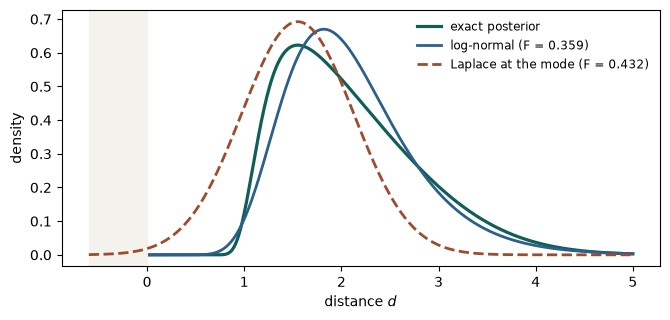

In [5]:
EXPECTED = {
    'w2_surp': 0.3263101797074492,
    'w2_mean': 2.0900306279919874,
    'w2_sd': 0.7210011172032382,
    'w2_mode': 1.5500361403975964,
    'lap_sd': 0.5760829280987836,
    'lap_F': 0.432471207276497,
    'ln_mr': 0.695547917476443,
    'ln_sr': 0.09720271313646882,
    'ln_F': 0.3587596166621332,
    'ln_mean_d': 2.1046501926148404,
    'ln_sd_d': 0.6724472900616625,
}

D_P, V_P, U_O, V_O, TH = 2.0, 1.0, 0.50, 0.10, 1.0
Z_P = 0.5 * (1.0 + erf(D_P / sqrt(2.0 * V_P)))

def ell(d):
    return (-(d - D_P) ** 2 / (2 * V_P) - 0.5 * np.log(2 * pi * V_P) - np.log(Z_P)
            - (U_O - TH / d ** 2) ** 2 / (2 * V_O) - 0.5 * np.log(2 * pi * V_O))

def ell_d1(d):
    return -(d - D_P) / V_P + (U_O - TH / d ** 2) / V_O * (-2 * TH / d ** 3)

def ell_d2(d):
    gp, gpp = -2 * TH / d ** 3, 6 * TH / d ** 4
    return -1 / V_P + ((U_O - TH / d ** 2) * gpp - gp ** 2) / V_O

def gl(a, b, npan, order=16):
    gx, gw = np.polynomial.legendre.leggauss(order)
    br = np.linspace(a, b, npan + 1)
    return ((0.5 * (br[:-1, None] + br[1:, None]) + 0.5 * np.diff(br)[:, None] * gx).ravel(),
            (0.5 * np.diff(br)[:, None] * gw).ravel())

def exact(npan):
    d, w = gl(1e-9, 12.0, npan)
    l = ell(d); mx = l.max()
    p = w * np.exp(l - mx)
    Z = p.sum(); p /= Z
    mean = np.sum(p * d)
    return -(mx + log(Z)), mean, sqrt(np.sum(p * (d - mean) ** 2))

surp, mean, sd = exact(300)
assert abs(exact(600)[0] - surp) < 1e-12
check('surprise -ln P(u)', surp, 'w2_surp', 1e-12)
check('posterior mean', mean, 'w2_mean', 1e-12)
check('posterior sd', sd, 'w2_sd', 1e-12)

scan = np.linspace(0.05, 12.0, 20000)
d_hat = scan[np.argmax(ell(scan))]
for _ in range(50):
    d_hat -= ell_d1(d_hat) / ell_d2(d_hat)
assert abs(ell_d1(d_hat)) < 1e-12 and ell_d2(d_hat) < 0
lap_var = -1 / ell_d2(d_hat)
lap_F = -ell(d_hat) - 0.5 * log(2 * pi * lap_var)
check('mode', d_hat, 'w2_mode', 1e-12)
check('Laplace sd', sqrt(lap_var), 'lap_sd', 1e-12)
check('Laplace free energy', lap_F, 'lap_F', 1e-12)

def ln_moments(m, S):        # E[d], E[d^2], E[d^-2], E[d^-4] under LN(m, S)
    return exp(m + 0.5 * S), exp(2 * m + 2 * S), exp(-2 * m + 2 * S), exp(-4 * m + 8 * S)

def F_ln(m, S):
    e1, e2, em2, em4 = ln_moments(m, S)
    e_prior = -(e2 - 2 * D_P * e1 + D_P ** 2) / (2 * V_P) - 0.5 * log(2 * pi * V_P) - log(Z_P)
    e_lik = -(U_O ** 2 - 2 * U_O * TH * em2 + TH ** 2 * em4) / (2 * V_O) - 0.5 * log(2 * pi * V_O)
    return -(e_prior + e_lik) - (0.5 * log(2 * pi * E_CONST * S) + m)

def grad_ln(m, S):
    e1, e2, em2, em4 = ln_moments(m, S)
    gm = (e2 - D_P * e1) / V_P + 2 * TH * (U_O * em2 - TH * em4) / V_O - 1
    gS = (2 * e2 - D_P * e1) / (2 * V_P) + 2 * TH * (2 * TH * em4 - U_O * em2) / V_O - 0.5 / S
    return np.array([gm, gS])

x = np.array([log(d_hat), 0.1])
for _ in range(60):
    H = np.column_stack([(grad_ln(*(x + e)) - grad_ln(*(x - e))) / 2e-6 for e in np.eye(2) * 1e-6])
    x = x - np.linalg.solve(0.5 * (H + H.T), grad_ln(*x))
assert np.max(np.abs(grad_ln(*x))) < 1e-12
fd = np.array([(F_ln(*(x + e)) - F_ln(*(x - e))) / 2e-6 for e in np.eye(2) * 1e-6])
assert np.max(np.abs(fd)) < 1e-8
m_ln, S_ln = x
check('log-normal m', m_ln, 'ln_mr', 1e-10)
check('log-normal S', S_ln, 'ln_sr', 1e-10)
check('log-normal free energy', F_ln(m_ln, S_ln), 'ln_F', 1e-12)
check('log-normal mean', exp(m_ln + 0.5 * S_ln), 'ln_mean_d', 1e-10)
check('log-normal sd', sqrt((exp(S_ln) - 1) * exp(2 * m_ln + S_ln)), 'ln_sd_d', 1e-10)

dd = np.linspace(-0.6, 5.0, 600)
pos = dd > 0.02
fig, ax = plt.subplots(figsize=(6.8, 3.3))
ax.axvspan(-0.6, 0.0, color='#f4f2ec')
ax.plot(dd[pos], np.exp(ell(dd[pos]) + surp), color=COL['accent'], lw=2.3, label='exact posterior')
ax.plot(dd[pos], np.exp(-(np.log(dd[pos]) - m_ln) ** 2 / (2 * S_ln)) / (dd[pos] * sqrt(2 * pi * S_ln)),
        color=COL['blue'], lw=2.0, label=f'log-normal (F = {F_ln(m_ln, S_ln):.3f})')
ax.plot(dd, np.exp(-(dd - d_hat) ** 2 / (2 * lap_var)) / sqrt(2 * pi * lap_var),
        color=COL['clay'], lw=2.0, ls='--', label=f'Laplace at the mode (F = {lap_F:.3f})')
ax.set_xlabel('distance $d$')
ax.set_ylabel('density')
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

## 5. The two-cause model

Lesson 5's model: $s_i \sim \mathrm{Exp}(\lambda_i)$, $u_1 = s_2 s_1^2 + z_1$,
$u_2 = s_1 s_2^2 + z_2$ with unit Gaussian noise, 500 trials drawn at
$\lambda^{*} = (0.9, 0.7)$. The next cell is the code that computed the lesson's
numbers, copied unchanged:

* `TrialGrid` integrates the exact posterior of one trial numerically, in the
  coordinates $y_i = (\text{noiseless output } i)^{1/3}$ in which the likelihood
  factorises;
* `newton_min` is the modified Newton method used for the Exponential and Gamma
  products, with its three stopping rules;
* `cavi` is coordinate ascent for the free-form product, each factor integrated by
  one-dimensional quadrature;
* `em` runs variational EM with warm-started E-steps, keeps the previous $Q$ on any
  trial where a new solve is not lower, and asserts that no E-step and no M-step
  raises the total free energy (the average-of-rates run is checked after its
  E-steps only, since its update is not an M-step);
* `ema_online` is the online rule that averages rates.
* `jacobian_implicit` computes the Jacobian of the EM map for the Exponential and Gamma
  families from the implicit-function formula of Lesson 5, with each trial's Hessian and
  no eigenvalue repair; `jacobian` computes it by central differences of the map.

In [6]:
LN2PI = log(2.0 * pi)
LAM_TRUE = (0.9, 0.7)
LAM_INIT = (2.0, 0.5)
N_TRIALS = 500
SEED = 42
REP_U = (2.5, 3.0)          # the representative trial, also the widget default


# ── sample ───────────────────────────────────────────────────────────────
def mulberry32(seed):
    a = [seed & 0xFFFFFFFF]

    def imul(x, y):
        return ((x & 0xFFFFFFFF) * (y & 0xFFFFFFFF)) & 0xFFFFFFFF

    def rnd():
        a[0] = (a[0] + 0x6D2B79F5) & 0xFFFFFFFF
        t = imul(a[0] ^ (a[0] >> 15), 1 | a[0])
        t = ((t + imul(t ^ (t >> 7), 61 | t)) & 0xFFFFFFFF) ^ t
        return ((t ^ (t >> 14)) & 0xFFFFFFFF) / 4294967296
    return rnd


def sample(n=N_TRIALS, seed=SEED, lam=LAM_TRUE):
    """Exponential draws by inversion, Gaussian noise by Box-Muller, in the order
    s1, s2, z1, z2 per trial, exactly as w04.js and both notebooks draw them."""
    rf = mulberry32(seed)

    def normal():
        a, b = rf(), rf()
        return sqrt(-2.0 * log(1.0 - a)) * cos(2.0 * pi * b)
    s1 = np.empty(n); s2 = np.empty(n); u1 = np.empty(n); u2 = np.empty(n)
    for i in range(n):
        a = -log(1.0 - rf()) / lam[0]
        b = -log(1.0 - rf()) / lam[1]
        s1[i], s2[i] = a, b
        u1[i] = b * a * a + normal()
        u2[i] = b * b * a + normal()
    return s1, s2, u1, u2


# ── reference integration ────────────────────────────────────────────────
# With g1 = s2 s1^2, g2 = s1 s2^2 and y_i = g_i^(1/3): s1 = y1^2/y2, s2 = y2^2/y1, and
# the Jacobian d(s1, s2)/d(y1, y2) has determinant 3. So
#   P(u | lam) = (3 lam1 lam2 / 2 pi) * integral over y > 0 of
#                exp(-lam1 y1^2/y2 - lam2 y2^2/y1 - (u1 - y1^3)^2/2 - (u2 - y2^3)^2/2).
# The likelihood factorises in y, so each axis is laid out from its own observation.
DEFAULT_QUAD = dict(L=10.0, hy=1.5, ngrade=14, ratio=0.25, order=8)
# each refinement changes one setting of DEFAULT_QUAD
QUAD_VARIANTS = {"hy": dict(hy=0.75), "L": dict(L=14.0), "grade": dict(ngrade=24, ratio=0.2),
                 "order": dict(order=12)}


def gl_panels(breaks, order=8):
    gx, gw = np.polynomial.legendre.leggauss(order)
    a = breaks[:-1][:, None]
    b = breaks[1:][:, None]
    return ((0.5 * (a + b) + 0.5 * (b - a) * gx[None, :]).ravel(),
            (0.5 * (b - a) * gw[None, :]).ravel())


def y_nodes(u, L=10.0, hy=1.5, ngrade=14, ratio=0.25, order=8):
    """Nodes in y = g^(1/3) for one sensor. Panels of width hy in g over
    [max(0, u - L), max(u, 0) + L] (L noise standard deviations either side), mapped
    to y; when that range reaches g = 0 the first panel is replaced by panels graded
    geometrically towards y = 0."""
    glo = max(0.0, u - L)
    ghi = max(u, 0.0) + L
    npan = int(np.ceil((ghi - glo) / hy))
    yb = np.cbrt(np.linspace(glo, ghi, npan + 1))
    if glo == 0.0:
        grade = yb[1] * ratio ** np.arange(ngrade, 0, -1)
        yb = np.concatenate([[0.0], grade, yb[1:]])
    return gl_panels(yb, order)


class TrialGrid:
    """Tensor-product nodes for one trial; the parts that do not depend on lambda."""

    def __init__(self, u1, u2, **quad):
        q = dict(DEFAULT_QUAD, **quad)
        x1, v1 = y_nodes(u1, **q)
        x2, v2 = y_nodes(u2, **q)
        Y1, Y2 = np.meshgrid(x1, x2, indexing="ij")
        self.s1 = (Y1 * Y1 / Y2).ravel()
        self.s2 = (Y2 * Y2 / Y1).ravel()
        self.lw = (np.log(np.outer(v1, v2)) - 0.5 * (u1 - Y1 ** 3) ** 2
                   - 0.5 * (u2 - Y2 ** 3) ** 2).ravel()

    def post(self, r1, r2, full=True):
        lf = self.lw - r1 * self.s1 - r2 * self.s2
        mx = lf.max()
        p = np.exp(lf - mx)
        Z = p.sum()
        nll = -(mx + log(Z) + log(3.0 * r1 * r2) - LN2PI)
        p /= Z
        m1 = (p * self.s1).sum()
        m2 = (p * self.s2).sum()
        out = dict(nll=nll, m1=m1, m2=m2)
        if full:
            d1 = self.s1 - m1
            d2 = self.s2 - m2
            v1 = (p * d1 * d1).sum()
            v2 = (p * d2 * d2).sum()
            c = (p * d1 * d2).sum()
            out.update(v1=v1, v2=v2, sd1=sqrt(v1), sd2=sqrt(v2), corr=c / sqrt(v1 * v2))
        return out


def exact_batch(grids, r1, r2, full=True):
    rows = [g.post(r1, r2, full) for g in grids]
    return {k: np.array([r[k] for r in rows]) for k in rows[0]}


# ── vectorised modified Newton ───────────────────────────────────────────
def newton_min(f, gh, x0, tol, maxit=200):
    """Minimise f row by row. Modified Newton (Hessian eigenvalues floored to make it
    positive definite), steps capped at 2 in every coordinate, backtracking with an
    Armijo condition. A row stops when its largest gradient component is below tol,
    when its Newton decrement is at the rounding level of f, or when no step lowers f
    (it is then at the rounding floor). Returns x, f, max |gradient| per row."""
    x = x0.copy()
    fx = f(x)
    n, _ = x.shape
    frozen = np.zeros(n, bool)
    for _ in range(maxit):
        g, H = gh(x)
        gn = np.max(np.abs(g), axis=1)
        ev, V = np.linalg.eigh(H)
        pd = ev.min(axis=1) > 0
        evf = np.maximum(np.abs(ev), 1e-8 * np.maximum(1.0, np.abs(ev).max(axis=1, keepdims=True)))
        step = -np.einsum("nij,nj->ni", V, np.einsum("nji,nj->ni", V, g) / evf)
        dec = -np.einsum("ni,ni->n", g, step)
        done = (dec <= 1e-28 * (1.0 + np.abs(fx)) ** 2) | (gn <= tol) | frozen
        local = pd & (dec < 1e-10 * (1.0 + np.abs(fx))) & ~done
        active = ~done
        if not active.any():
            break
        sn = np.max(np.abs(step), axis=1, keepdims=True)
        step = step * np.minimum(1.0, 2.0 / np.maximum(sn, 1e-300))
        t = np.ones((n, 1))
        accepted = ~active | local
        xn = x.copy(); fn = fx.copy()
        if local.any():
            xn[local] = x[local] + step[local]
            fn[local] = f(xn)[local]
        for _ in range(80):
            if accepted.all():
                break
            cand = x + t * step
            fc = f(cand)
            ok = (fc <= fx - 1e-4 * t[:, 0] * dec) & ~accepted
            ok |= (fc < fx) & ~accepted & (t[:, 0] < 1e-8)
            xn[ok] = cand[ok]; fn[ok] = fc[ok]
            accepted |= ok
            t[~accepted] *= 0.5
        frozen |= ~accepted
        x = xn; fx = fn
    g, _ = gh(x)
    return x, fx, np.max(np.abs(g), axis=1)


# ── product of Exponentials, parameterised by ln means ───────────────────
# F = sum_i [ -ln m_i - ln lam_i + lam_i m_i - 1 ] + ln 2pi
#     + u1^2/2 - 2 u1 m1^2 m2 + 24 m1^4 m2^2 + u2^2/2 - 2 u2 m1 m2^2 + 24 m1^2 m2^4
def F_exp(x, u1, u2, r1, r2):
    a, b = x[:, 0], x[:, 1]
    return (-a - np.log(r1) + r1 * np.exp(a) - 1.0 - b - np.log(r2) + r2 * np.exp(b) - 1.0 + LN2PI
            + 0.5 * u1 * u1 - 2.0 * u1 * np.exp(2 * a + b) + 24.0 * np.exp(4 * a + 2 * b)
            + 0.5 * u2 * u2 - 2.0 * u2 * np.exp(a + 2 * b) + 24.0 * np.exp(2 * a + 4 * b))


def gh_exp(x, u1, u2, r1, r2):
    a, b = x[:, 0], x[:, 1]
    A = np.exp(a); B = np.exp(b)
    E1 = np.exp(2 * a + b); E2 = np.exp(4 * a + 2 * b)
    E3 = np.exp(a + 2 * b); E4 = np.exp(2 * a + 4 * b)
    g1 = -1.0 + r1 * A - 4 * u1 * E1 + 96 * E2 - 2 * u2 * E3 + 48 * E4
    g2 = -1.0 + r2 * B - 2 * u1 * E1 + 48 * E2 - 4 * u2 * E3 + 96 * E4
    h11 = r1 * A - 8 * u1 * E1 + 384 * E2 - 2 * u2 * E3 + 96 * E4
    h12 = -4 * u1 * E1 + 192 * E2 - 4 * u2 * E3 + 192 * E4
    h22 = r2 * B - 2 * u1 * E1 + 96 * E2 - 8 * u2 * E3 + 384 * E4
    g = np.stack([g1, g2], -1)
    H = np.stack([np.stack([h11, h12], -1), np.stack([h12, h22], -1)], -2)
    return g, H


EXP_TOL = 1e-10


def solve_exp(u1, u2, r1, r2, x0):
    return newton_min(lambda x: F_exp(x, u1, u2, r1, r2),
                      lambda x: gh_exp(x, u1, u2, r1, r2), x0, EXP_TOL)


# ── product of Gammas, parameterised by ln means and ln shapes ───────────
def digamma(x):
    x = np.array(x, dtype=float, copy=True)
    out = np.zeros_like(x)
    while np.any(x < 10.0):
        m = x < 10.0
        out = np.where(m, out - 1.0 / x, out)
        x = np.where(m, x + 1.0, x)
    i = 1.0 / x; i2 = i * i
    return out + np.log(x) - 0.5 * i - i2 * (1/12 - i2 * (1/120 - i2 * (1/252 - i2 * (1/240 - i2 / 132))))


def trigamma(x):
    x = np.array(x, dtype=float, copy=True)
    out = np.zeros_like(x)
    while np.any(x < 10.0):
        m = x < 10.0
        out = np.where(m, out + 1.0 / (x * x), out)
        x = np.where(m, x + 1.0, x)
    i = 1.0 / x; i2 = i * i
    return out + i + 0.5 * i2 + i * i2 * (1/6 - i2 * (1/30 - i2 * (1/42 - i2 * (1/30 - i2 * 5/66))))


_lgam = np.vectorize(lgamma)


def _gam_pieces(x):
    m1, m2, k1, k2 = np.exp(x[:, 0]), np.exp(x[:, 1]), np.exp(x[:, 2]), np.exp(x[:, 3])
    c21, c22 = 1 + 1 / k1, 1 + 1 / k2
    c41 = c21 * (1 + 2 / k1) * (1 + 3 / k1)
    c42 = c22 * (1 + 2 / k2) * (1 + 3 / k2)
    return m1, m2, k1, k2, c21, c22, c41, c42


def F_gam(x, u1, u2, r1, r2):
    """KL(q_i || Exp(lam_i)) = -ln Gamma(k) + (k-1) psi(k) + ln k - k - ln m - ln lam + lam m;
    E[s^2] = m^2 (1 + 1/k), E[s^4] = m^4 (1+1/k)(1+2/k)(1+3/k)."""
    m1, m2, k1, k2, c21, c22, c41, c42 = _gam_pieces(x)
    kl1 = -_lgam(k1) + (k1 - 1) * digamma(k1) + np.log(k1) - k1 - x[:, 0] - np.log(r1) + r1 * m1
    kl2 = -_lgam(k2) + (k2 - 1) * digamma(k2) + np.log(k2) - k2 - x[:, 1] - np.log(r2) + r2 * m2
    e1 = u1 * u1 - 2 * u1 * m2 * m1 ** 2 * c21 + m2 ** 2 * c22 * m1 ** 4 * c41
    e2 = u2 * u2 - 2 * u2 * m1 * m2 ** 2 * c22 + m1 ** 2 * c21 * m2 ** 4 * c42
    return kl1 + kl2 + LN2PI + 0.5 * e1 + 0.5 * e2


def grad_gam(x, u1, u2, r1, r2):
    m1, m2, k1, k2, c21, c22, c41, c42 = _gam_pieces(x)
    dc21, dc22 = -1 / k1, -1 / k2                       # d c2 / d ln k
    dc41 = -c41 * (1 / (k1 + 1) + 2 / (k1 + 2) + 3 / (k1 + 3))   # d c4 / d ln k
    dc42 = -c42 * (1 / (k2 + 1) + 2 / (k2 + 2) + 3 / (k2 + 3))
    T1 = u1 * m2 * m1 ** 2 * c21
    Q1 = m2 ** 2 * c22 * m1 ** 4 * c41
    T2 = u2 * m1 * m2 ** 2 * c22
    Q2 = m1 ** 2 * c21 * m2 ** 4 * c42
    g_a1 = -1 + r1 * m1 + (-2 * T1 + 2 * Q1) + (-T2 + Q2)
    g_a2 = -1 + r2 * m2 + (-T1 + Q1) + (-2 * T2 + 2 * Q2)
    dkl1 = k1 * ((k1 - 1) * trigamma(k1) + 1 / k1 - 1)
    dkl2 = k2 * ((k2 - 1) * trigamma(k2) + 1 / k2 - 1)
    g_k1 = dkl1 - T1 * dc21 / c21 + 0.5 * Q1 * dc41 / c41 + 0.5 * Q2 * dc21 / c21
    g_k2 = dkl2 + 0.5 * Q1 * dc22 / c22 - T2 * dc22 / c22 + 0.5 * Q2 * dc42 / c42
    return np.stack([g_a1, g_a2, g_k1, g_k2], -1)


def _gh_fd(grad, h=1e-6):
    def gh(x):
        g0 = grad(x)
        n, p = x.shape
        H = np.empty((n, p, p))
        for j in range(p):
            e = np.zeros(p); e[j] = h
            H[:, :, j] = (grad(x + e) - grad(x - e)) / (2 * h)
        return g0, 0.5 * (H + np.transpose(H, (0, 2, 1)))
    return gh


GAM_TOL = 1e-9


def solve_gam(u1, u2, r1, r2, x0):
    return newton_min(lambda x: F_gam(x, u1, u2, r1, r2),
                      _gh_fd(lambda x: grad_gam(x, u1, u2, r1, r2)), x0, GAM_TOL)


# ── free-form mean-field ─────────────────────────────────────────────────
# ln q1(s1) = -E[s2^2]/2 s1^4 + (u1 E[s2] - E[s2^4]/2) s1^2 + (u2 E[s2^2] - lam1) s1 + const,
# and the same with the indices exchanged. Each factor is a density on s > 0 of the form
# exp(a s^4 + b s^2 + c s) with a < 0, integrated by 1-D quadrature.
FF_QUAD = dict(npan=32, ncoarse=256, window=60.0)


def quartic_moments(a, b, c, npan=32, ncoarse=256, window=60.0):
    """Rows of exp(a s^4 + b s^2 + c s) on s > 0, a < 0. A coarse scan finds where the
    exponent is within `window` nats of its maximum; composite 8-point Gauss-Legendre
    on that interval. Returns ln Z, E[s], E[s^2], E[s^4], and the interval."""
    n = a.shape[0]
    shi = 2.0 * np.maximum.reduce([np.ones(n), np.sqrt(np.abs(b / a)), np.cbrt(np.abs(c / a))]) + 1.0
    P = lambda s: a[:, None] * s ** 4 + b[:, None] * s ** 2 + c[:, None] * s
    t = np.linspace(0.0, 1.0, ncoarse)[None, :]
    Pc = P(shi[:, None] * t)
    keep = Pc > Pc.max(axis=1, keepdims=True) - window
    idx = np.arange(ncoarse)[None, :]
    lo = shi * np.maximum(np.where(keep, idx, ncoarse).min(axis=1) - 1, 0) / (ncoarse - 1)
    hi = shi * np.minimum(np.where(keep, idx, -1).max(axis=1) + 1, ncoarse - 1) / (ncoarse - 1)
    xs, ws = gl_panels(np.linspace(0, 1, npan + 1))
    s = lo[:, None] + (hi - lo)[:, None] * xs[None, :]
    w = (hi - lo)[:, None] * ws[None, :]
    Ps = P(s)
    m = Ps.max(axis=1, keepdims=True)
    e = np.exp(Ps - m) * w
    Z = e.sum(axis=1)
    p = e / Z[:, None]
    s2 = s * s
    return m[:, 0] + np.log(Z), (p * s).sum(1), (p * s2).sum(1), (p * s2 * s2).sum(1)


def ff_coef1(u1, u2, r1, mom2):
    e1, e2, e4 = mom2
    return -0.5 * e2, u1 * e1 - 0.5 * e4, u2 * e2 - r1


def ff_coef2(u1, u2, r2, mom1):
    e1, e2, e4 = mom1
    return -0.5 * e2, u2 * e1 - 0.5 * e4, u1 * e2 - r2


def F_ff(u1, u2, r1, r2, mom1, mom2, co1, lnZ1, co2, lnZ2):
    a1, a2, a4 = mom1
    b1, b2, b4 = mom2
    elnq1 = co1[0] * a4 + co1[1] * a2 + co1[2] * a1 - lnZ1
    elnq2 = co2[0] * b4 + co2[1] * b2 + co2[2] * b1 - lnZ2
    elnp = (np.log(r1) + np.log(r2) - r1 * a1 - r2 * b1 - LN2PI
            - 0.5 * (u1 * u1 - 2 * u1 * b1 * a2 + b2 * a4)
            - 0.5 * (u2 * u2 - 2 * u2 * b2 * a1 + b4 * a2))
    return elnq1 + elnq2 - elnp


FF_TOL = 1e-12


def cavi(u1, u2, r1, r2, mom2, tol=FF_TOL, maxsweep=20000, quad=None):
    """Sequential coordinate ascent, q1 then q2, starting from q2's moments. A trial stops
    when one sweep changes E[s1] and E[s2] by a relative amount below tol. Free energy
    never rises from sweep to sweep (asserted). Returns the moments of q1 and q2, F,
    and sweeps per trial."""
    kw = dict(FF_QUAD, **(quad or {}))
    n = u1.shape[0]
    mom2 = tuple(np.array(m, float, copy=True) for m in mom2)
    mom1 = tuple(np.zeros(n) for _ in range(3))
    F = np.full(n, np.inf)
    act = np.arange(n)
    sweeps = np.zeros(n, int)
    for _ in range(maxsweep):
        ua, va = u1[act], u2[act]
        co1 = ff_coef1(ua, va, r1, tuple(m[act] for m in mom2))
        lnZ1, *m1n = quartic_moments(*co1, **kw)
        co2 = ff_coef2(ua, va, r2, m1n)
        lnZ2, *m2n = quartic_moments(*co2, **kw)
        Fn = F_ff(ua, va, r1, r2, m1n, m2n, co1, lnZ1, co2, lnZ2)
        Fo = F[act]
        dm = np.maximum(np.abs(m1n[0] - mom1[0][act]) / m1n[0],
                        np.abs(m2n[0] - mom2[0][act]) / m2n[0])
        assert np.all(Fn <= Fo + 1e-9 * (1 + np.abs(Fo))), np.max(Fn - Fo)
        for M, Mn in ((mom1, m1n), (mom2, m2n)):
            for j in range(3):
                M[j][act] = Mn[j]
        F[act] = Fn
        sweeps[act] += 1
        act = act[~(dm < tol)]
        if act.size == 0:
            break
    assert act.size == 0, "coordinate ascent did not meet its tolerance"
    return mom1, mom2, F, sweeps


# ── families for variational EM ──────────────────────────────────────────
class Exact:
    name = "exact"

    def __init__(self, u1, u2, quad=None):
        self.grids = [TrialGrid(a, b, **(quad or {})) for a, b in zip(u1, u2)]

    def init(self, lam):
        return None

    def estep(self, lam, st):
        ex = exact_batch(self.grids, lam[0], lam[1], full=False)
        return None, ex["nll"], ex["m1"], ex["m2"]


EXP_STARTS = [(a, b) for a in (-2.0, 0.0, 1.5) for b in (-2.0, 0.0, 1.5)]
GAM_STARTS = [(a, k) for a in (-1.0, 0.0, 1.0) for k in (0.0, 2.0, 5.0)]


class ExpMF:
    name = "exp"

    def __init__(self, u1, u2):
        self.u1, self.u2 = u1, u2

    def multistart(self, lam, starts=EXP_STARTS):
        n = len(self.u1)
        best = None
        for a0, b0 in starts:
            x, f, _ = solve_exp(self.u1, self.u2, lam[0], lam[1], np.tile([a0, b0], (n, 1)))
            if best is None:
                best = [x, f]
            else:
                m = f < best[1]
                best[0][m] = x[m]; best[1][m] = f[m]
        return best[0]

    init = multistart

    def F(self, lam, x):
        return F_exp(x, self.u1, self.u2, lam[0], lam[1])

    def estep(self, lam, x0):
        x, f, g = solve_exp(self.u1, self.u2, lam[0], lam[1], x0)
        f0 = self.F(lam, x0)
        bad = f > f0              # keep the previous Q where the new one is not lower
        x[bad] = x0[bad]; f[bad] = f0[bad]
        self.gmax = float(g.max())
        return x, f, np.exp(x[:, 0]), np.exp(x[:, 1])


class GamMF:
    name = "gam"

    def __init__(self, u1, u2):
        self.u1, self.u2 = u1, u2

    def multistart(self, lam, starts=GAM_STARTS):
        n = len(self.u1)
        best = None
        for a0, k0 in starts:
            x, f, _ = solve_gam(self.u1, self.u2, lam[0], lam[1], np.tile([a0, a0, k0, k0], (n, 1)))
            if best is None:
                best = [x, f]
            else:
                m = f < best[1]
                best[0][m] = x[m]; best[1][m] = f[m]
        return best[0]

    init = multistart

    def F(self, lam, x):
        return F_gam(x, self.u1, self.u2, lam[0], lam[1])

    def estep(self, lam, x0):
        x, f, g = solve_gam(self.u1, self.u2, lam[0], lam[1], x0)
        f0 = self.F(lam, x0)
        bad = f > f0
        x[bad] = x0[bad]; f[bad] = f0[bad]
        self.gmax = float(g.max())
        return x, f, np.exp(x[:, 0]), np.exp(x[:, 1])


class FreeMF:
    name = "free"

    def __init__(self, u1, u2, quad=None):
        self.u1, self.u2, self.quad = u1, u2, quad

    def prior_moments(self, lam):
        n = len(self.u1); r = lam[1]
        return (np.full(n, 1 / r), np.full(n, 2 / r ** 2), np.full(n, 24 / r ** 4))

    init = prior_moments

    def estep(self, lam, mom2):
        m1, m2, F, sw = cavi(self.u1, self.u2, lam[0], lam[1], mom2, quad=self.quad)
        self.mom1, self.sweeps = m1, sw
        return m2, F, m1[0], m2[0]


def prior_shift(F, lam_old, lam_new, m1, m2):
    """Per-trial F after the prior rates change with Q held fixed: only the term
    -ln lam_i + lam_i E_q[s_i] of each KL depends on lam."""
    return (F - np.log(lam_new[0]) + lam_new[0] * m1 + np.log(lam_old[0]) - lam_old[0] * m1
              - np.log(lam_new[1]) + lam_new[1] * m2 + np.log(lam_old[1]) - lam_old[1] * m2)


EM_TOL = 1e-11


def em(fam, lam0=LAM_INIT, rule="HM", tol=EM_TOL, maxit=3000, state=None):
    """Variational EM from lam0. rule 'HM' is the M-step lam_i = 1/mean E_q[s_i], which
    minimises total F over lam; 'AM' sets lam_i = mean of 1/E_q[s_i], which is not an
    M-step of F. Every E-step is warm-started from the previous Q and checked not to
    raise total F; every HM M-step is checked likewise. Stops when lam changes by a
    relative amount below tol."""
    lam = np.array(lam0, float)
    st = fam.init(lam) if state is None else state
    st, F, m1, m2 = fam.estep(lam, st)
    Ftot = [F.sum()]; lams = [lam.copy()]; Fm_list = []
    rises = 0
    for it in range(maxit):
        if rule == "HM":
            new = np.array([1 / m1.mean(), 1 / m2.mean()])
        else:
            new = np.array([(1 / m1).mean(), (1 / m2).mean()])
        Fm = prior_shift(F, lam, new, m1, m2).sum()
        if rule == "HM":
            assert Fm <= Ftot[-1] + 1e-10 * abs(Ftot[-1]), ("M-step raised F", Fm - Ftot[-1])
        Fm_list.append(Fm)
        lam_old, lam = lam, new
        st, F, m1, m2 = fam.estep(lam, st)
        assert F.sum() <= Fm + 1e-10 * abs(Fm), ("E-step raised F", F.sum() - Fm)
        rises += F.sum() > Ftot[-1] + 1e-10 * abs(Ftot[-1])
        Ftot.append(F.sum()); lams.append(lam.copy())
        if np.max(np.abs(lam - lam_old) / lam) < tol:
            break
    else:
        raise RuntimeError("EM did not converge")
    return dict(lam=lam, F=F, m1=m1, m2=m2, state=st, its=it + 1, rises=int(rises),
                Ftot=np.array(Ftot), Fm=np.array(Fm_list), lams=np.array(lams))


def m_map(fam, lam, st):
    st2, _, m1, m2 = fam.estep(np.asarray(lam, float), st)
    return np.array([1 / m1.mean(), 1 / m2.mean()]), st2


def hess_gam(x, u1, u2, r1, r2, h=1e-5):
    """Hessian of F_gam: central differences of the analytic gradient, symmetrised,
    with no eigenvalue repair."""
    p = x.shape[1]
    H = np.empty((x.shape[0], p, p))
    for j in range(p):
        e = np.zeros(p); e[j] = h
        H[:, :, j] = (grad_gam(x + e, u1, u2, r1, r2) - grad_gam(x - e, u1, u2, r1, r2)) / (2 * h)
    return 0.5 * (H + np.transpose(H, (0, 2, 1)))


def _fam_gh(fam, lam, x):
    if fam.name == "exp":
        return gh_exp(x, fam.u1, fam.u2, lam[0], lam[1])
    return (grad_gam(x, fam.u1, fam.u2, lam[0], lam[1]),
            hess_gam(x, fam.u1, fam.u2, lam[0], lam[1]))


def jacobian_implicit(fam, lam, x, polish=8):
    """The M-map Jacobian of a parametric family from [eq:tc-jac-param]:
    J_ij = sum_n h_ni^T H_n^{-1} h_nj / (N mbar_i^2), with H_n the Hessian of F_n at the
    E-step solution (no eigenvalue repair) and h_ni = grad_x E_q[s_i] = m_i e_i in the
    ln-mean coordinates. Each solution is first polished by plain Newton steps, a step
    kept only where it does not raise F. Returns J, the smallest Hessian eigenvalue over
    trials and the largest gradient component after polishing."""
    lam = np.asarray(lam, float)
    x = x.copy()
    for _ in range(polish):
        g, H = _fam_gh(fam, lam, x)
        cand = x - np.linalg.solve(H, g[..., None])[..., 0]
        ok = fam.F(lam, cand) <= fam.F(lam, x)
        x[ok] = cand[ok]
    g, H = _fam_gh(fam, lam, x)
    mineig = float(np.linalg.eigvalsh(H).min())
    assert mineig > 0, ("Hessian not positive definite at an E-step solution", mineig)
    m = np.exp(x[:, :2])
    hv = np.zeros((len(x), x.shape[1], 2))
    hv[:, 0, 0] = m[:, 0]; hv[:, 1, 1] = m[:, 1]
    J = np.einsum("nki,nkj->ij", hv, np.linalg.solve(H, hv)) / len(x)
    J /= m.mean(axis=0)[:, None] ** 2
    return J, mineig, float(np.abs(g).max())


JAC_FD_STEPS = (1e-3, 3e-3, 1e-2)


def jacobian(fam, lam, st, h=1e-5):
    J = np.zeros((2, 2))
    for j in range(2):
        e = np.zeros(2); e[j] = h * lam[j]
        Mp, _ = m_map(fam, lam + e, st)
        Mm, _ = m_map(fam, lam - e, st)
        J[:, j] = (Mp - Mm) / (2 * e[j])
    return J


def ema_online(u1, u2, mu0=LAM_INIT, keep=0.99):
    """The notebook's loop: one pass over the trials; on each, the Exponential q at the
    current prior rates (best of 25 starts) and mu <- keep mu + (1 - keep) (1/m1, 1/m2)."""
    mu = np.array(mu0, float)
    starts = np.array([[a, b] for a in (-3, -1.5, 0, 1.5, 3) for b in (-3, -1.5, 0, 1.5, 3)], float)
    traj = [mu.copy()]
    for n in range(len(u1)):
        k = len(starts)
        x, f, _ = solve_exp(np.full(k, u1[n]), np.full(k, u2[n]), mu[0], mu[1], starts.copy())
        j = int(np.argmin(f))
        mu = keep * mu + (1 - keep) * np.exp(-x[j])
        traj.append(mu.copy())
    return np.array(traj)


def grad_diag(fam, lam, x, tol):
    """Largest |gradient| over trials at x, the number of trials above the stopping
    tolerance, and the largest Newton decrement g' H^-1 g among those trials (the
    decrease a further Newton step predicts)."""
    u1, u2 = fam.u1, fam.u2
    if fam.name == "exp":
        g, H = gh_exp(x, u1, u2, lam[0], lam[1])
    else:
        g, H = _gh_fd(lambda z: grad_gam(z, u1, u2, lam[0], lam[1]))(x)
    gn = np.max(np.abs(g), axis=1)
    over = gn > tol
    dec = 0.0
    if over.any():
        dec = float(np.max(np.einsum("ni,ni->n", g[over], np.linalg.solve(H[over], g[over][..., None])[..., 0])))
    return dict(gmax=float(gn.max()), over=int(over.sum()), dec=dec)

In [7]:
EXPECTED = {
    'tc_quad_nodes': 29303.0,
    'tc_qc_hy_nll': 2.7244777101032014e-08,
    'tc_qc_hy_m': 1.0056183542710318e-07,
    'tc_qc_hy_sd': 2.7813574799138335e-06,
    'tc_qc_L_nll': 2.1344625622532476e-08,
    'tc_qc_L_m': 1.5158649281852302e-08,
    'tc_ex_corr': -0.542902279413698,
    'tc_ema_1': 3.099182410048965,
    'tc_ema_2': 2.0689361562702278,
    'tc_rises_am': 38.0,
    'tc_its_am': 129.0,
    'tc_jc_exact_11': 0.2910082102887899,
    'tc_jc_exact_12': -0.14342467931280842,
    'tc_jc_exact_21': -0.08083414696564731,
    'tc_jc_exact_22': 0.262885894252208,
    'tc_jt_exact_11': 0.29100821029458424,
    'tc_jt_exact_12': -0.14342467931559102,
    'tc_jt_exact_21': -0.08083414696244715,
    'tc_jt_exact_22': 0.26288589425961717,
    'tc_jt_gam_11': 0.22712399159371705,
    'tc_jt_gam_12': -0.11782084404130143,
    'tc_jt_gam_21': -0.06985539535301609,
    'tc_jt_gam_22': 0.18899293882103885,
    'tc_jf_gam_rho': 0.2852483764176449,
    'tc_gain_gam_11': 1.3110840424145431,
    'tc_gain_gam_22': 1.249440911048892,
    'tc_jt_exp_11': 0.42619068438005614,
    'tc_jt_exp_12': -0.32641678184395184,
    'tc_jt_exp_21': -0.2226191671825592,
    'tc_jt_exp_22': 0.3527540197009783,
    'tc_jf_exp_rho': 0.5603882746867195,
    'tc_gain_exp_11': 2.166665021114642,
    'tc_gain_exp_22': 1.9208347533793766,
    'tc_pin_exact_1': 0.9225221002771115,
    'tc_pin_exact_2': 0.6925677511647158,
    'tc_fit_exact_1': 0.9344697057876346,
    'tc_fit_exact_2': 0.6861578872980507,
    'tc_its_exact': 27.0,
    'tc_pin_free_1': 1.0174262599095918,
    'tc_pin_free_2': 0.7838716551630022,
    'tc_fit_free_1': 1.0353614072930921,
    'tc_fit_free_2': 0.7904619402357512,
    'tc_its_free': 21.0,
    'tc_pin_gam_1': 1.0378188619791473,
    'tc_pin_gam_2': 0.7991171886378986,
    'tc_fit_gam_1': 1.0614944366330206,
    'tc_fit_gam_2': 0.8084203519015665,
    'tc_its_gam': 48.0,
    'tc_pin_exp_1': 2.071684971450819,
    'tc_pin_exp_2': 1.7108768625538346,
    'tc_fit_exp_1': 2.351874230594615,
    'tc_fit_exp_2': 1.8277360374526885,
    'tc_its_exp': 53.0,
    'tc_pin_am_1': 2.340894614563823,
    'tc_pin_am_2': 2.0014919029881293,
    'tc_fit_am_1': 2.8344830714790334,
    'tc_fit_am_2': 2.3068478132260672,
}

t0 = perf_counter()
s1, s2, u1, u2 = sample()
lt = np.array(LAM_TRUE)
exf = Exact(u1, u2)
ex = exact_batch(exf.grids, *lt)
check('nodes per trial (average, rounded down)', int(np.mean([g.s1.size for g in exf.grids])), 'tc_quad_nodes', 0)
check('mean posterior correlation', ex['corr'].mean(), 'tc_ex_corr', 1e-9)

# halve the panel width, then widen the limits, and compare
for tag, q in (('hy', dict(hy=0.75)), ('L', dict(L=14.0))):
    e2 = exact_batch([TrialGrid(a, b, **q) for a, b in zip(u1, u2)], *lt)
    d_nll = np.max(np.abs(e2['nll'] - ex['nll']))
    d_m = max(np.max(np.abs(e2[f] - ex[f]) / ex[f]) for f in ('m1', 'm2'))
    print(f'{tag}: largest change in -ln P(u) {d_nll:.1e}, relative change in the means {d_m:.1e}')
    check(f'{tag}: change in -ln P(u)', d_nll, f'tc_qc_{tag}_nll', 1e-12)
    del e2
print(f'exact posteriors: {perf_counter() - t0:.1f} s')

ok       nodes per trial (average, rounded down)  29303   lesson  29303
ok       mean posterior correlation             -0.5429022794   lesson -0.5429022794


hy: largest change in -ln P(u) 2.7e-08, relative change in the means 1.0e-07
ok       hy: change in -ln P(u)                  2.72447771e-08   lesson  2.72447771e-08


L: largest change in -ln P(u) 2.1e-08, relative change in the means 1.5e-08
ok       L: change in -ln P(u)                   2.134462562e-08   lesson  2.134462562e-08
exact posteriors: 1.3 s


In [8]:
# one E-step at the true rates for each family, then the M-step; and the average of rates
t0 = perf_counter()
fams = {'exact': exf, 'free': FreeMF(u1, u2), 'gam': GamMF(u1, u2), 'exp': ExpMF(u1, u2)}
pin_state = {}
print(f"{'family':8s} {'lambda_1':>9s} {'lambda_2':>9s}   one M-step from the true rates (0.9, 0.7)")
for k, fam in fams.items():
    st, F, m1, m2 = fam.estep(lt, fam.init(lt))
    pin_state[k] = st
    lam = (1 / m1.mean(), 1 / m2.mean())
    print(f'{k:8s} {lam[0]:9.4f} {lam[1]:9.4f}')
    check(f'{k}: one-step rate 1', lam[0], f'tc_pin_{k}_1', 1e-8)
    check(f'{k}: one-step rate 2', lam[1], f'tc_pin_{k}_2', 1e-8)
    if k == 'exp':
        check('exp, average of rates, rate 1', (1 / m1).mean(), 'tc_pin_am_1', 1e-8)
        check('exp, average of rates, rate 2', (1 / m2).mean(), 'tc_pin_am_2', 1e-8)
print(f'one-step E-steps: {perf_counter() - t0:.1f} s')

family    lambda_1  lambda_2   one M-step from the true rates (0.9, 0.7)
exact       0.9225    0.6926
ok       exact: one-step rate 1                  0.9225221003   lesson  0.9225221003
ok       exact: one-step rate 2                  0.6925677512   lesson  0.6925677512


free        1.0174    0.7839
ok       free: one-step rate 1                   1.01742626   lesson  1.01742626
ok       free: one-step rate 2                   0.7838716552   lesson  0.7838716552


gam         1.0378    0.7991
ok       gam: one-step rate 1                    1.037818862   lesson  1.037818862
ok       gam: one-step rate 2                    0.7991171886   lesson  0.7991171886
exp         2.0717    1.7109
ok       exp: one-step rate 1                    2.071684971   lesson  2.071684971
ok       exp: one-step rate 2                    1.710876863   lesson  1.710876863
ok       exp, average of rates, rate 1           2.340894615   lesson  2.340894615
ok       exp, average of rates, rate 2           2.001491903   lesson  2.001491903
one-step E-steps: 2.3 s


In [9]:
# closed-loop variational EM from (2.0, 0.5) for every family, and the average of rates
t0 = perf_counter()
runs = {k: em(fam) for k, fam in fams.items()}
runs['am'] = em(fams['exp'], rule='AM')
for k, r in runs.items():
    print(f"{k:6s} fitted ({r['lam'][0]:.4f}, {r['lam'][1]:.4f}) after {r['its']} iterations")
    check(f'{k}: fitted rate 1', r['lam'][0], f'tc_fit_{k}_1', 1e-7)
    check(f'{k}: fitted rate 2', r['lam'][1], f'tc_fit_{k}_2', 1e-7)
    note(f'{k}: iterations', r['its'], f'tc_its_{k}')
note('average of rates: iterations where F rose', runs['am']['rises'], 'tc_rises_am')
for k in ('exact', 'free', 'gam', 'exp'):
    assert np.all(np.diff(runs[k]['Ftot']) <= 1e-10 * np.abs(runs[k]['Ftot'][1:])), k
print(f'variational EM: {perf_counter() - t0:.1f} s')

t0 = perf_counter()
ema = ema_online(u1, u2)
check('online rule, final rate 1', ema[-1, 0], 'tc_ema_1', 1e-9)
check('online rule, final rate 2', ema[-1, 1], 'tc_ema_2', 1e-9)
print(f'online rule: {perf_counter() - t0:.1f} s')

exact  fitted (0.9345, 0.6862) after 27 iterations
ok       exact: fitted rate 1                    0.9344697058   lesson  0.9344697058
ok       exact: fitted rate 2                    0.6861578873   lesson  0.6861578873
count    exact: iterations                       27   lesson  27
free   fitted (1.0354, 0.7905) after 21 iterations
ok       free: fitted rate 1                     1.035361407   lesson  1.035361407
ok       free: fitted rate 2                     0.7904619402   lesson  0.7904619402
count    free: iterations                        21   lesson  21
gam    fitted (1.0615, 0.8084) after 48 iterations
ok       gam: fitted rate 1                      1.061494437   lesson  1.061494437
ok       gam: fitted rate 2                      0.8084203519   lesson  0.8084203519
count    gam: iterations                         48   lesson  48
exp    fitted (2.3519, 1.8277) after 53 iterations
ok       exp: fitted rate 1                      2.351874231   lesson  2.351874231
ok       exp

ok       online rule, final rate 1               3.09918241   lesson  3.09918241
ok       online rule, final rate 2               2.068936156   lesson  2.068936156
online rule: 1.1 s


from covariances:


 [[ 0.291  -0.1434]
 [-0.0808  0.2629]] 
from central differences:
 [[ 0.291  -0.1434]
 [-0.0808  0.2629]]
ok       J[11] from covariances                  0.2910082103   lesson  0.2910082103
ok       J[11] from differences                  0.2910082103   lesson  0.2910082103
ok       J[12] from covariances                 -0.1434246793   lesson -0.1434246793
ok       J[12] from differences                 -0.1434246793   lesson -0.1434246793
ok       J[21] from covariances                 -0.08083414697   lesson -0.08083414697
ok       J[21] from differences                 -0.08083414696   lesson -0.08083414696
ok       J[22] from covariances                  0.2628858943   lesson  0.2628858943
ok       J[22] from differences                  0.2628858943   lesson  0.2628858943
gam: J at the true rates [[0.22712399, -0.11782084], [-0.0698554, 0.18899294]] smallest Hessian eigenvalue 0.120, differences with steps of 1e-3 of each rate agree to 7.2e-07
ok       gam: J[11] at the true ra

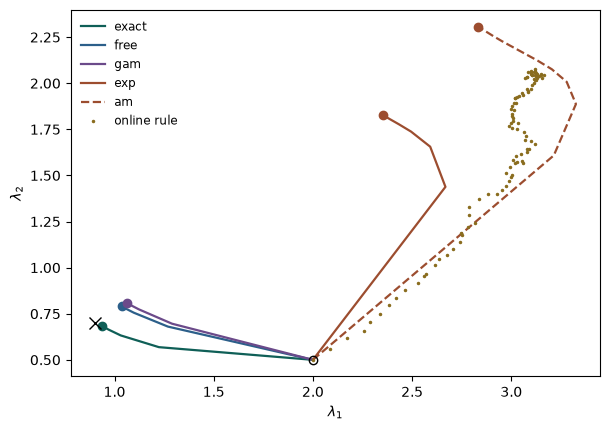

In [10]:
# the Jacobian of exact EM's map at the true rates: posterior covariances against differences
cov = np.array([[ex['v1'], ex['corr'] * ex['sd1'] * ex['sd2']],
                [ex['corr'] * ex['sd1'] * ex['sd2'], ex['v2']]]).mean(axis=2)
mbar = np.array([ex['m1'].mean(), ex['m2'].mean()])
J_cov = cov / mbar[:, None] ** 2
J_fd = jacobian(exf, lt, None)
print('from covariances:\n', J_cov, '\nfrom central differences:\n', J_fd)
for i in range(2):
    for j in range(2):
        check(f'J[{i + 1}{j + 1}] from covariances', J_cov[i, j], f'tc_jc_exact_{i + 1}{j + 1}', 1e-9)
        check(f'J[{i + 1}{j + 1}] from differences', J_fd[i, j], f'tc_jt_exact_{i + 1}{j + 1}', 1e-7)

# Exponential and Gamma: the implicit-function formula with each trial's Hessian, at the
# true rates and at the fitted rates, against central differences of the map
for k in ('gam', 'exp'):
    J_t, me, gr = jacobian_implicit(fams[k], lt, pin_state[k])
    J_f, _, _ = jacobian_implicit(fams[k], runs[k]['lam'], runs[k]['state'])
    J_d = jacobian(fams[k], lt, pin_state[k], h=1e-3)
    print(f'{k}: J at the true rates', J_t.round(8).tolist(), f'smallest Hessian eigenvalue {me:.3f}, '
          f'differences with steps of 1e-3 of each rate agree to {np.abs(J_d - J_t).max():.1e}')
    assert np.abs(J_d - J_t).max() < 1e-5
    for i in range(2):
        for j in range(2):
            check(f'{k}: J[{i + 1}{j + 1}] at the true rates', J_t[i, j], f'tc_jt_{k}_{i + 1}{j + 1}', 1e-9)
    G = np.linalg.inv(np.eye(2) - J_t)
    check(f'{k}: gain 11', G[0, 0], f'tc_gain_{k}_11', 1e-9)
    check(f'{k}: gain 22', G[1, 1], f'tc_gain_{k}_22', 1e-9)
    check(f'{k}: spectral radius at the fit', max(abs(np.linalg.eigvals(J_f))), f'tc_jf_{k}_rho', 1e-7)

fig, ax = plt.subplots(figsize=(6.2, 4.4))
style = {'exact': (COL['accent'], '-'), 'free': (COL['blue'], '-'), 'gam': (COL['violet'], '-'),
         'exp': (COL['clay'], '-'), 'am': (COL['clay'], '--')}
for k, (c, ls) in style.items():
    L = runs[k]['lams']
    ax.plot(L[:, 0], L[:, 1], color=c, ls=ls, lw=1.6, label=k)
    ax.plot(*L[-1], 'o', color=c)
ax.plot(ema[::5, 0], ema[::5, 1], '.', color=COL['gold'], ms=3, label='online rule')
ax.plot(*LAM_INIT, 'o', mfc='none', mec='k')
ax.plot(*LAM_TRUE, 'kx', ms=8)
ax.set_xlabel(r'$\lambda_1$')
ax.set_ylabel(r'$\lambda_2$')
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()